In [1]:
from dataclasses import asdict
from pathlib import Path

from IPython.display import Image, display
import numpy as np
from mpi4py import MPI

from src.config import Geometry
from src.mesh import MagnetronMesh, MeshSettings
from src.magnetostatics import MagnetostaticSettings, MagnetostaticSimulation
from src.visualization import (
    plot_magnetic_field,
    plot_target_surface_profile,
)


In [2]:
RESULTS_DIR = Path("results/variants")

DEFAULT_GEOMETRY = asdict(Geometry())
DEFAULT_MESH = asdict(MeshSettings(min_size=0.025, max_size=0.5))
DEFAULT_PHYSICS = asdict(MagnetostaticSettings())

VARIANTS = [
    {
        "name": "baseline",
        "geometry": {},
        "mesh": {},
        "physics": {},
    },
        {
        "name": "outer_magnet_diameter_10_new_baseline",
        "geometry": {"outer_magnet_diameter": 10},
        "mesh": {},
        "physics": {},
    },
]


Info    : Meshing 1D...nts - Adding holes                                                                                
Info    : [  0%] Meshing curve 15 (Line)
Info    : [ 10%] Meshing curve 16 (Line)
Info    : [ 10%] Meshing curve 17 (Line)
Info    : [ 20%] Meshing curve 18 (Line)
Info    : [ 20%] Meshing curve 19 (Line)
Info    : [ 20%] Meshing curve 20 (Line)
Info    : [ 30%] Meshing curve 21 (Line)
Info    : [ 30%] Meshing curve 22 (Line)
Info    : [ 40%] Meshing curve 23 (Line)
Info    : [ 40%] Meshing curve 24 (Line)
Info    : [ 40%] Meshing curve 25 (Line)
Info    : [ 50%] Meshing curve 26 (Line)
Info    : [ 50%] Meshing curve 27 (Line)
Info    : [ 60%] Meshing curve 28 (Line)
Info    : [ 60%] Meshing curve 29 (Line)
Info    : [ 60%] Meshing curve 30 (Line)
Info    : [ 70%] Meshing curve 31 (Line)
Info    : [ 70%] Meshing curve 32 (Line)
Info    : [ 70%] Meshing curve 33 (Line)
Info    : [ 80%] Meshing curve 34 (Line)
Info    : [ 80%] Meshing curve 35 (Line)
Info    : [ 90%] 

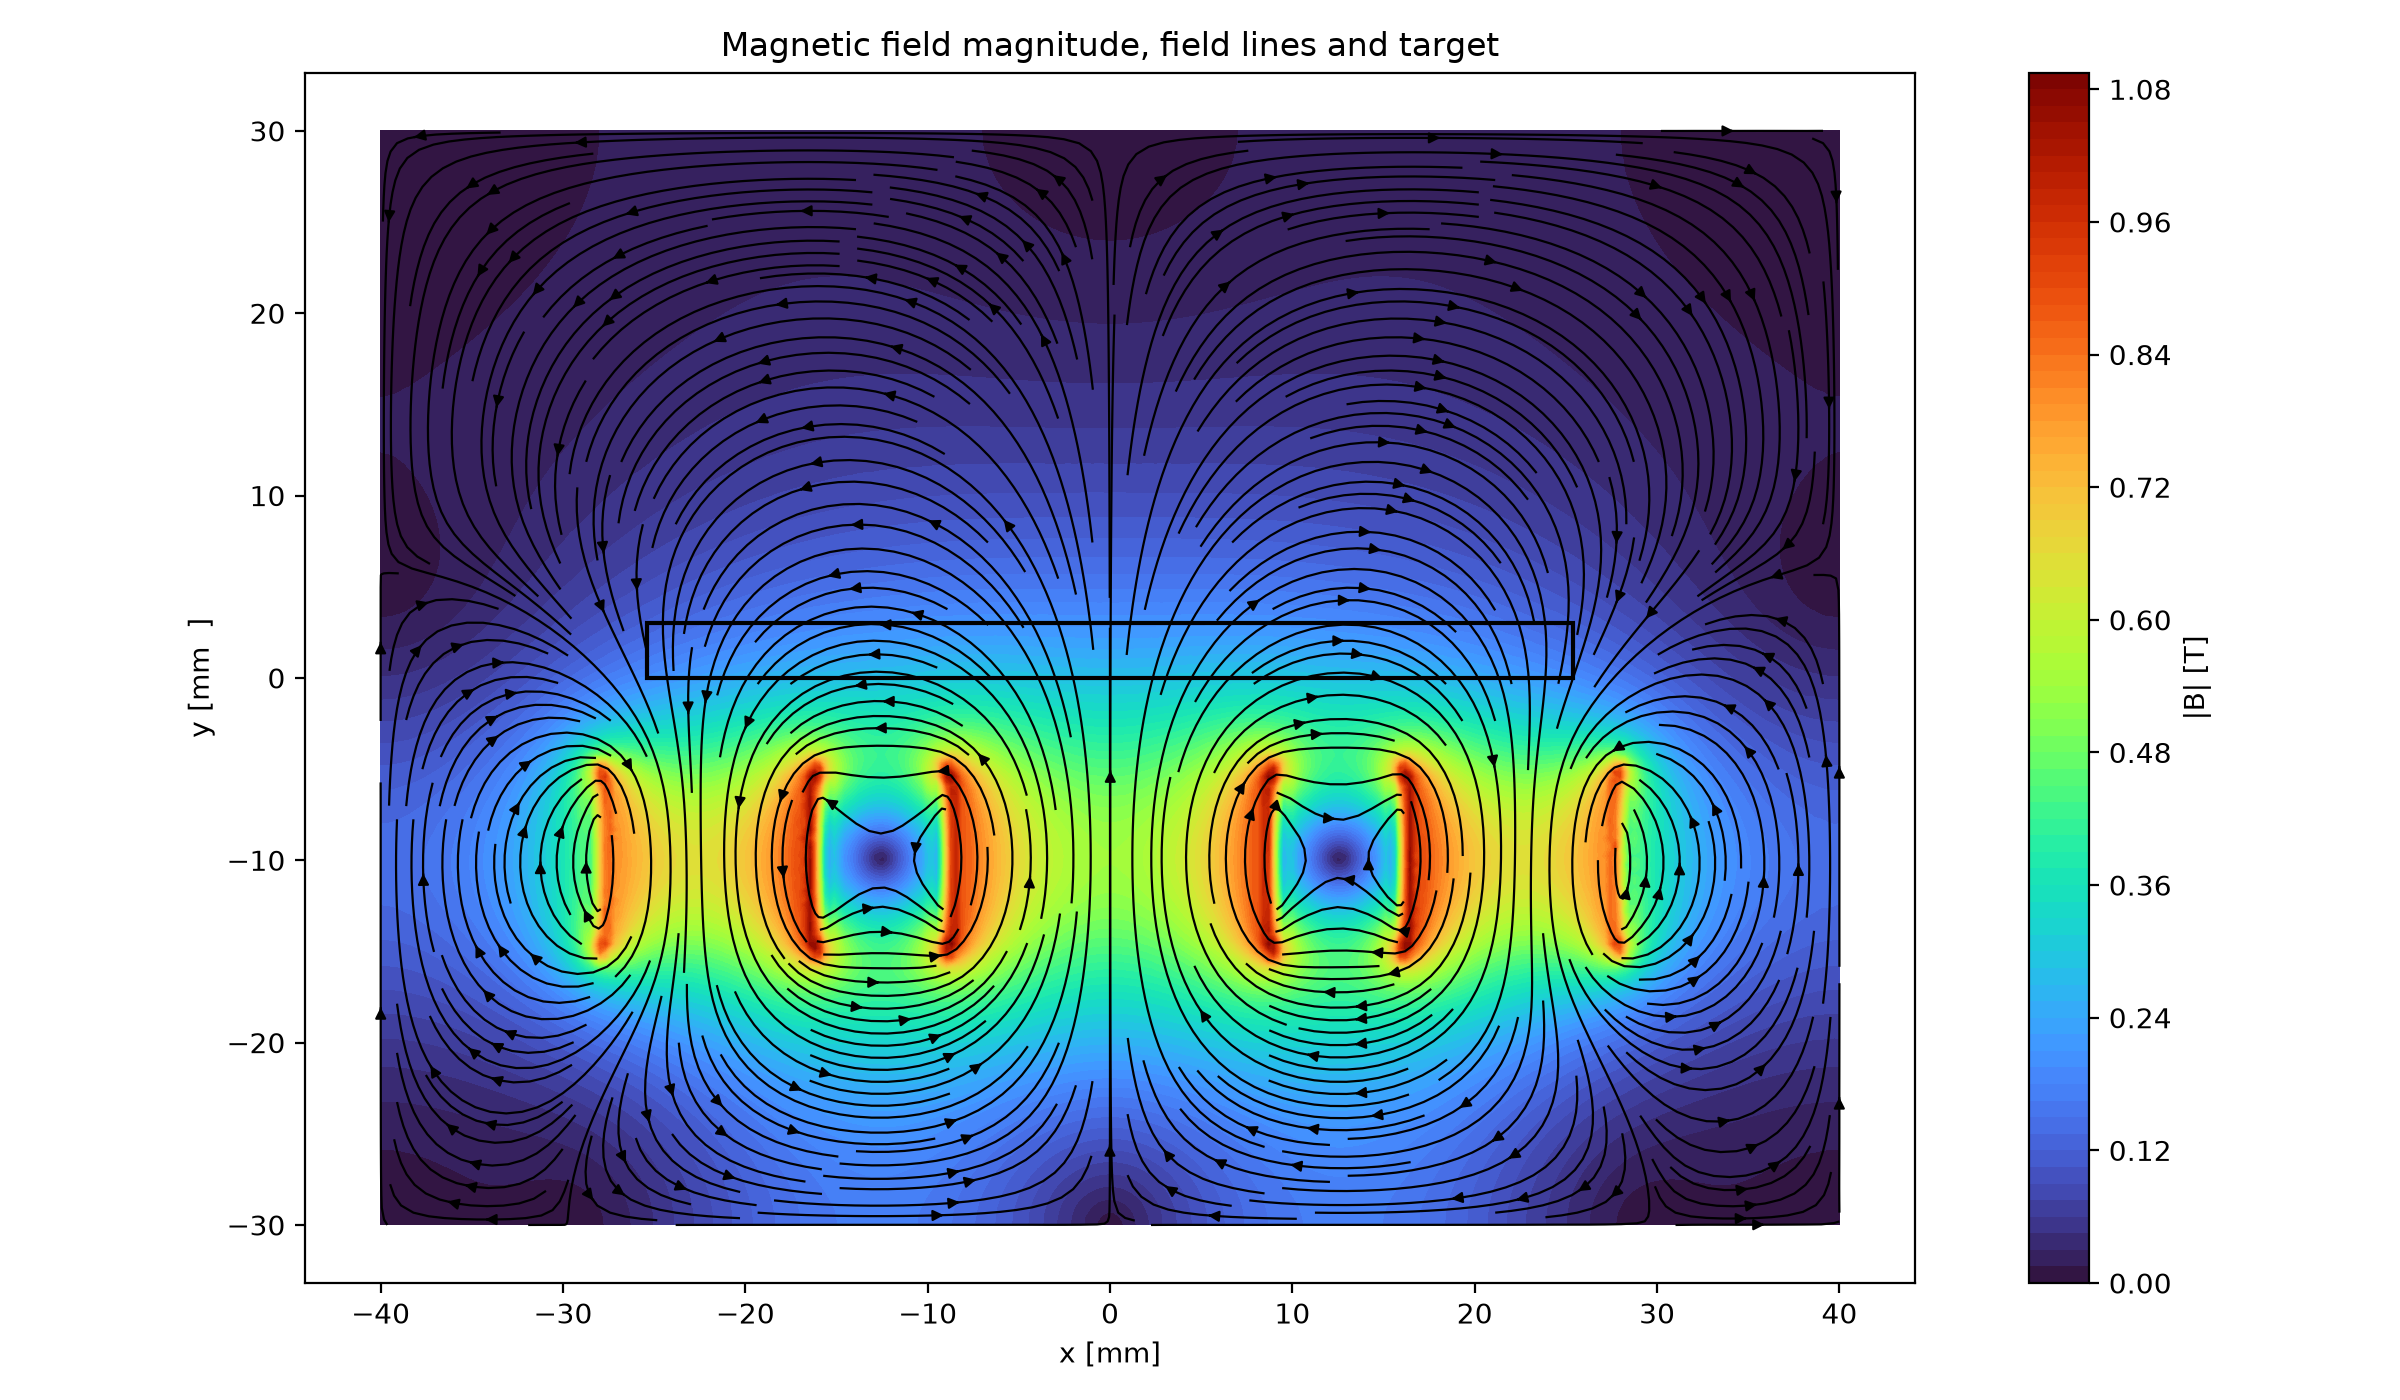

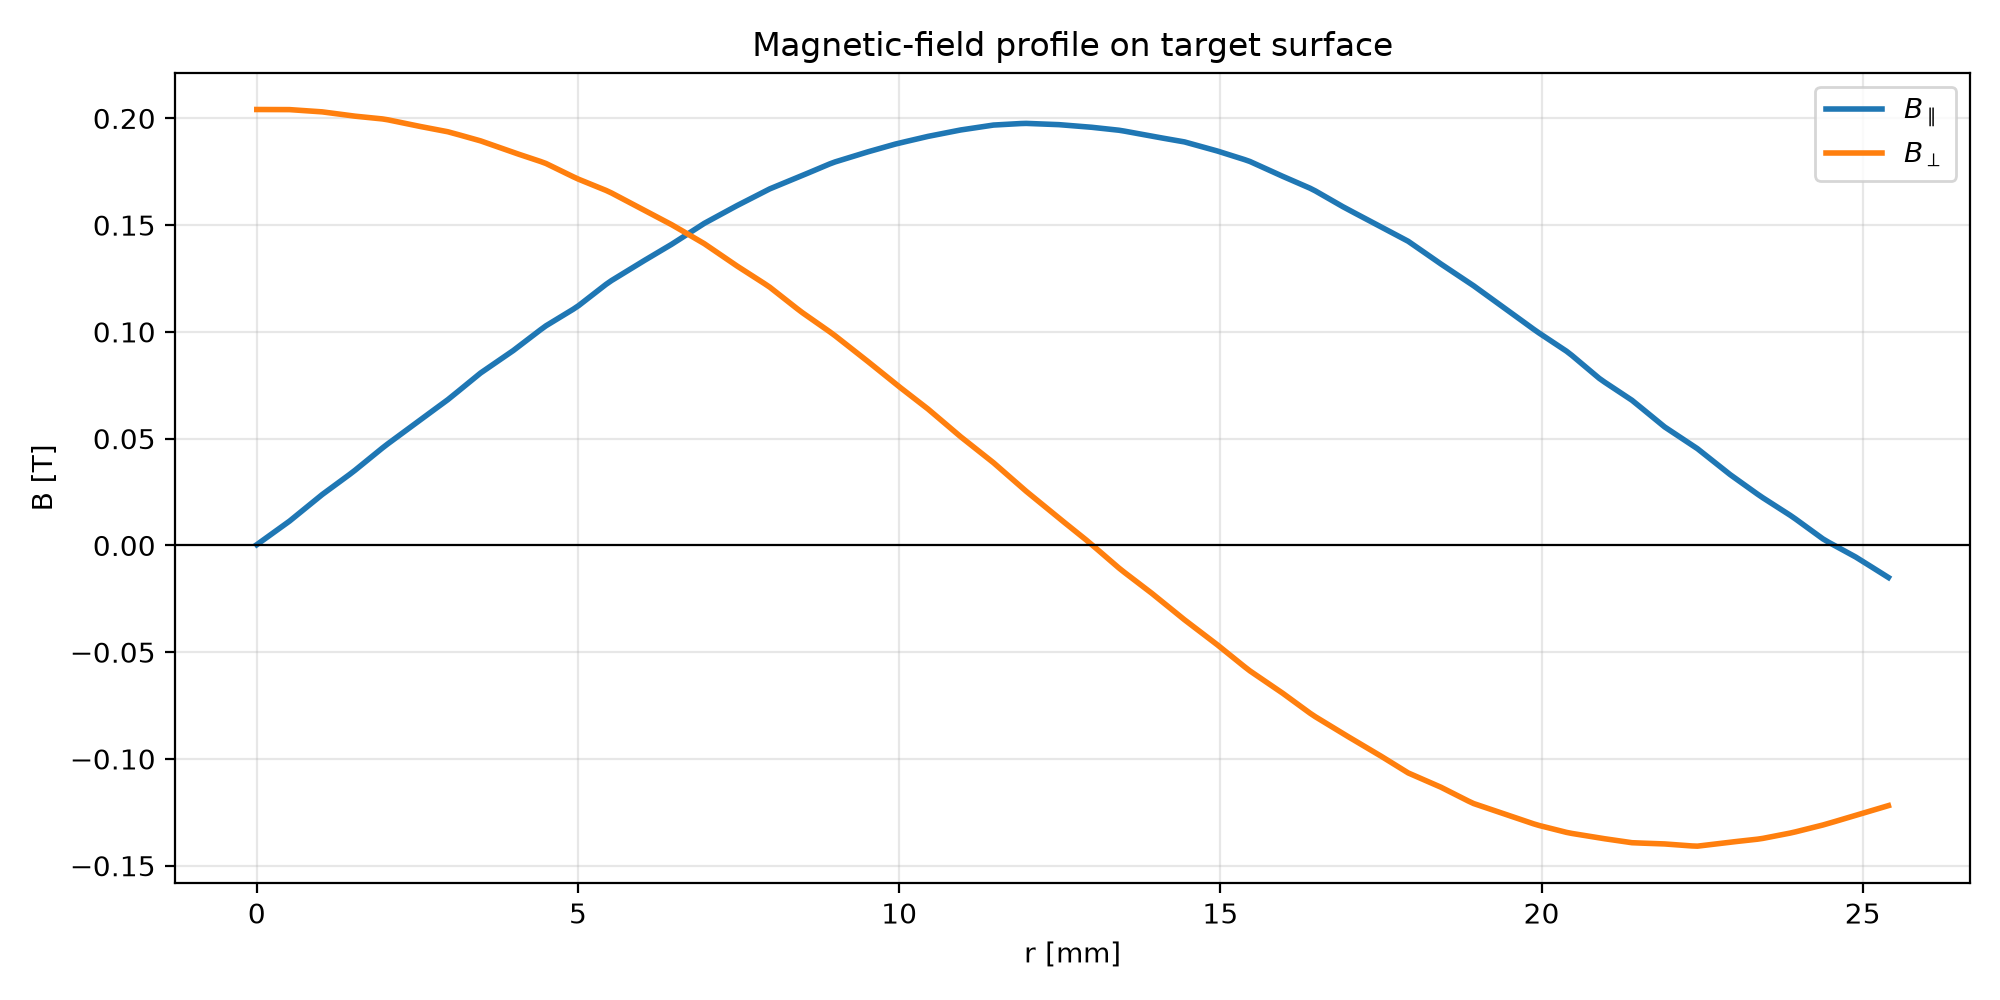

Profile data: results/variants/baseline/target_surface_profile.csv
Info    : Meshing 1D...nts - Adding holes                                                                                
Info    : [  0%] Meshing curve 15 (Line)
Info    : [ 10%] Meshing curve 16 (Line)
Info    : [ 10%] Meshing curve 17 (Line)
Info    : [ 20%] Meshing curve 18 (Line)
Info    : [ 20%] Meshing curve 19 (Line)
Info    : [ 20%] Meshing curve 20 (Line)
Info    : [ 30%] Meshing curve 21 (Line)
Info    : [ 30%] Meshing curve 22 (Line)
Info    : [ 40%] Meshing curve 23 (Line)
Info    : [ 40%] Meshing curve 24 (Line)
Info    : [ 40%] Meshing curve 25 (Line)
Info    : [ 50%] Meshing curve 26 (Line)
Info    : [ 50%] Meshing curve 27 (Line)
Info    : [ 60%] Meshing curve 28 (Line)
Info    : [ 60%] Meshing curve 29 (Line)
Info    : [ 60%] Meshing curve 30 (Line)
Info    : [ 70%] Meshing curve 31 (Line)
Info    : [ 70%] Meshing curve 32 (Line)
Info    : [ 70%] Meshing curve 33 (Line)
Info    : [ 80%] Meshing curve 3

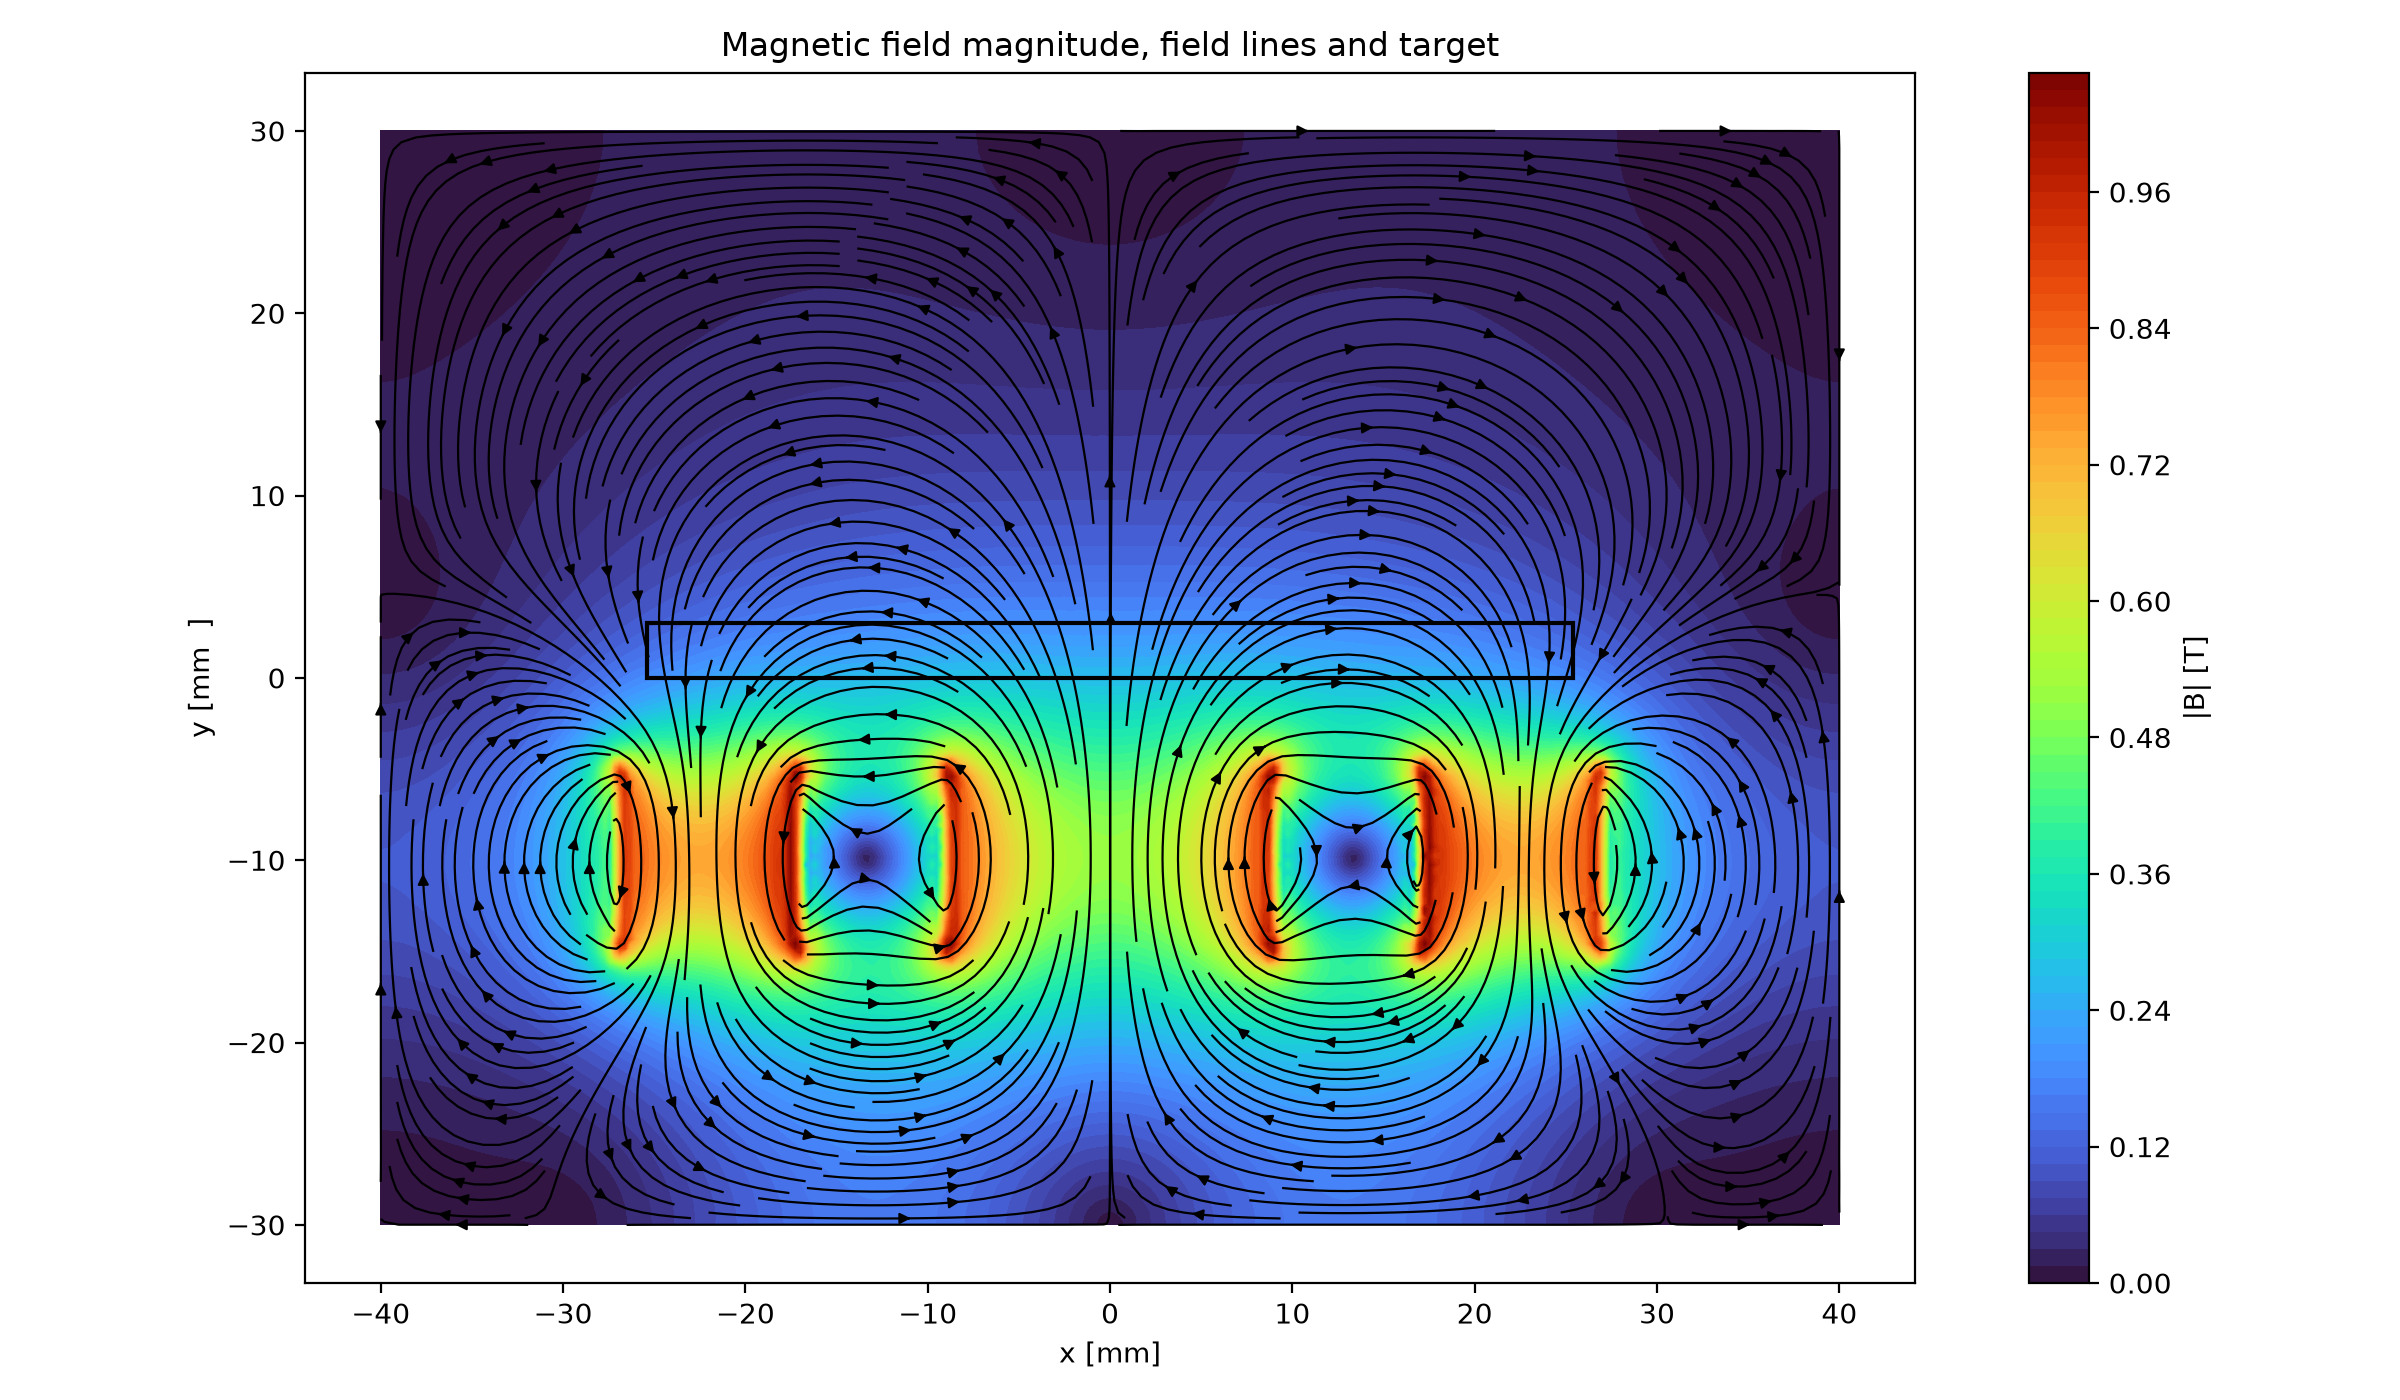

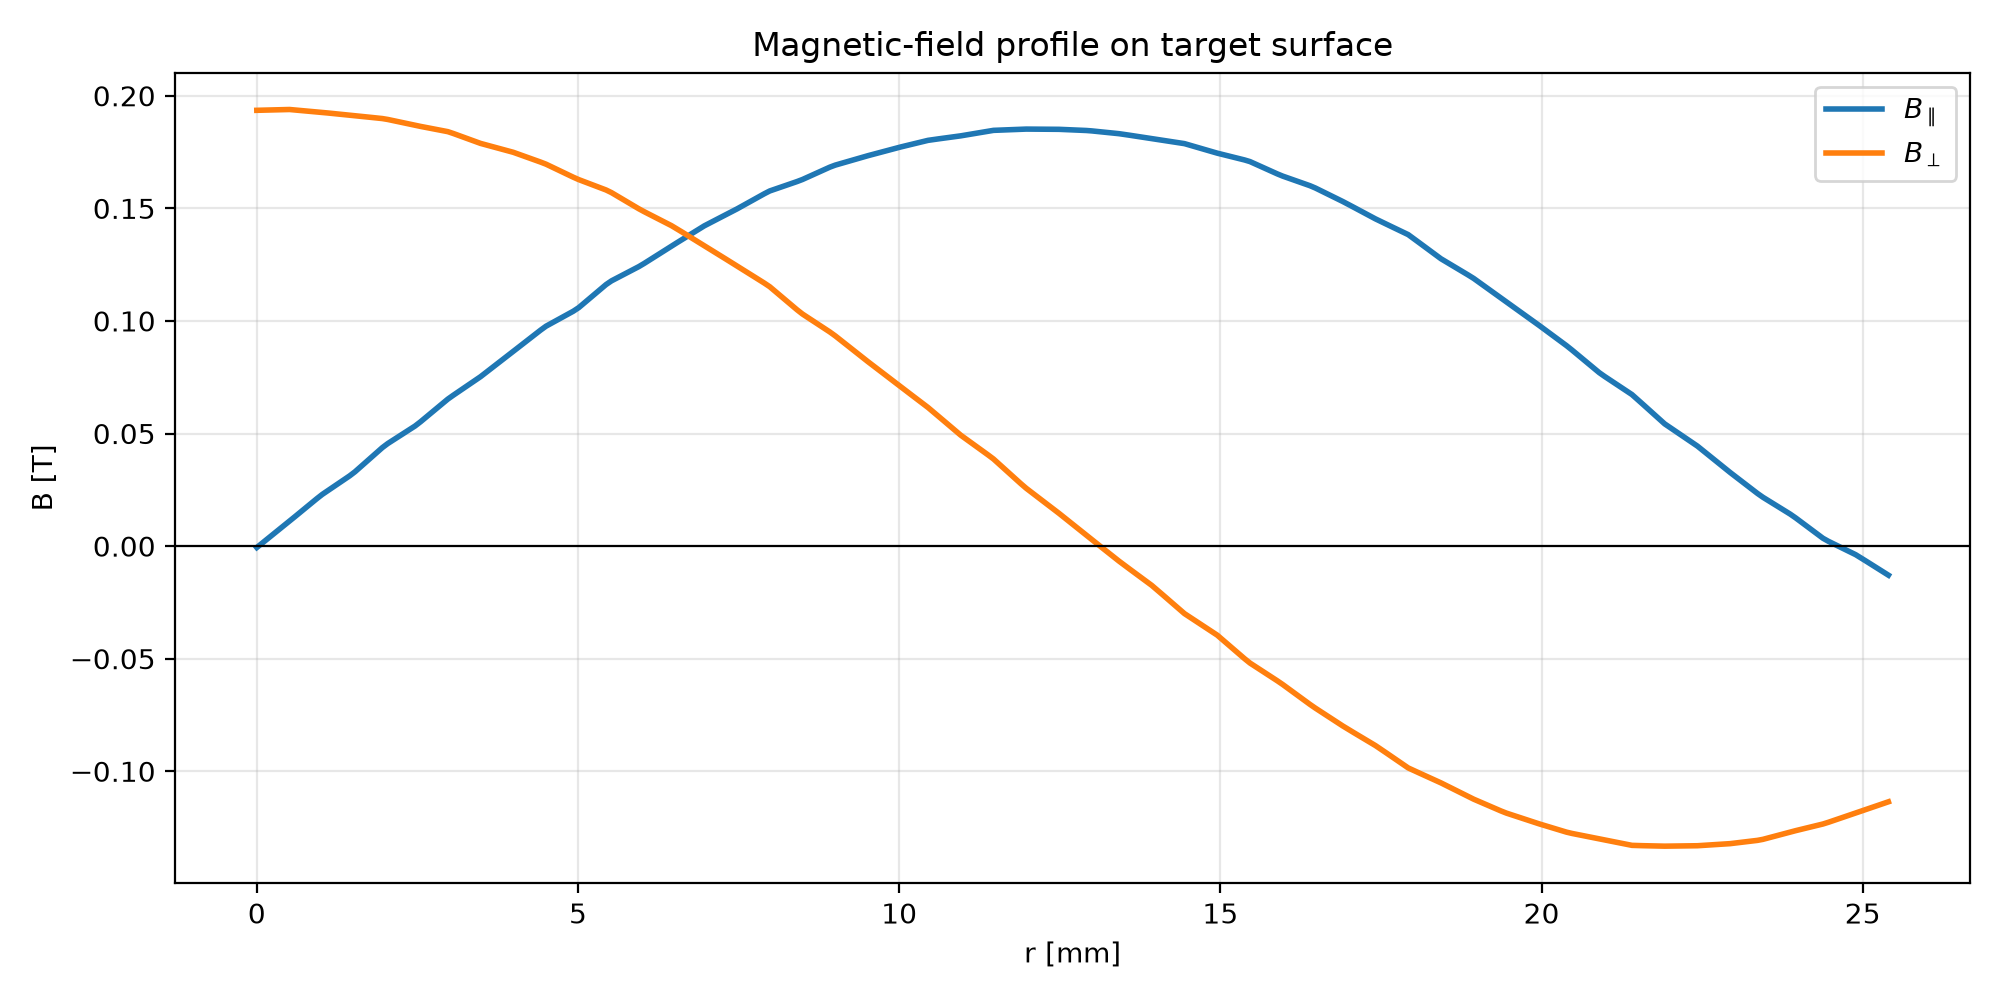

Profile data: results/variants/outer_magnet_diameter_10_new_baseline/target_surface_profile.csv


In [3]:
if MPI.COMM_WORLD.size != 1:
    raise RuntimeError("This notebook must be run with one MPI process.")

for variant in VARIANTS:
    name = variant["name"]
    case_dir = RESULTS_DIR / name

    geometry = Geometry(**(DEFAULT_GEOMETRY | variant["geometry"]))
    mesh_settings = MeshSettings(**(DEFAULT_MESH | variant["mesh"]))
    physics_settings = MagnetostaticSettings(
        **(DEFAULT_PHYSICS | variant["physics"])
    )

    mesh_path = MagnetronMesh(geometry, mesh_settings).generate(
        case_dir / "mesh.msh"
    )
    result = MagnetostaticSimulation(mesh_path, physics_settings).solve(case_dir)
    field_plot_path = plot_magnetic_field(
        result,
        case_dir / f"field_{name}.png",
        target_diameter=geometry.target_diameter,
        target_thickness=geometry.target_thickness,
    )
    profile_plot_path = case_dir / f"target_surface_profile_{name}.png"
    radius, b_parallel, b_perpendicular = plot_target_surface_profile(
        result,
        profile_plot_path,
        target_diameter=geometry.target_diameter,
        target_thickness=geometry.target_thickness,
    )
    profile_data_path = case_dir / "target_surface_profile.csv"
    np.savetxt(
        profile_data_path,
        np.column_stack((radius, b_parallel, b_perpendicular)),
        delimiter=",",
        header="r,B_parallel,B_perpendicular",
        comments="",
    )

    print(f"===== {name} =====")
    print(f"Mesh: {mesh_path}")
    print(f"Field data: {result.fields_file}")
    display(Image(filename=str(field_plot_path)))
    display(Image(filename=str(profile_plot_path)))
    print(f"Profile data: {profile_data_path}")
